# Notebook 07 — Impact of Realism Improvements on ML Models

This notebook quantifies how the v3 simulation improvements affected model performance relative to a v2-style baseline.

**Approach:**
1. Reproduce v2-style metrics (no new v3 columns) on the v3 dataset
2. Compare feature importance — which v3 columns drive predictive power
3. Analyse per-event-type and per-UE-type performance
4. Show how RF risk evolves in the steps leading up to a handover

In [1]:
import sys, json
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, torch
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, roc_auc_score, precision_score, recall_score,
    classification_report, confusion_matrix
)
from src.models import load_splits, xy, LSTMClassifier, SequenceDataset, SEQ_LEN

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110
MODELS_DIR = Path('../models')
LABEL = 'handover_soon'

# Load raw dataset (used by several cells below)
raw = pd.read_csv('../data/raw/dataset.csv')

train, val, test, feat_cols, meta = load_splits()
X_train, y_train = xy(train, feat_cols)
X_test,  y_test  = xy(test,  feat_cols)

rf   = joblib.load(MODELS_DIR / 'random_forest.pkl')
lr   = joblib.load(MODELS_DIR / 'logistic_regression.pkl')
lstm = LSTMClassifier(input_size=len(feat_cols))
lstm.load_state_dict(torch.load(MODELS_DIR / 'lstm.pt', map_location='cpu'))
lstm.eval()

rf_probs = rf.predict_proba(X_test)[:, 1]
lr_probs = lr.predict_proba(X_test)[:, 1]

ds = SequenceDataset(test, feat_cols, seq_len=SEQ_LEN)
loader = torch.utils.data.DataLoader(ds, batch_size=512, shuffle=False)
lstm_probs, lstm_labels = [], []
with torch.no_grad():
    for xb, yb in loader:
        lstm_probs.extend(torch.sigmoid(lstm(xb)).numpy())
        lstm_labels.extend(yb.numpy().astype(int))
lstm_probs  = np.array(lstm_probs)
lstm_labels = np.array(lstm_labels)

print('Models and data loaded.')
print(f'Test set: {len(X_test):,} rows | {y_test.sum()} positives')
print(f'Raw dataset: {len(raw):,} rows')

Models and data loaded.
Test set: 8,100 rows | 605 positives
Raw dataset: 54,000 rows


## 1. v2 vs v3 — Simulated Comparison

We simulate the v2-style scenario by training a Random Forest on the **v2 feature set**
(no `l3_rsrp_serving`, `l3_rsrp_neighbor`, `los_flag`, `cell_load_pct`) and comparing
against the full v3 model. Both use the same train/test split from the v3 dataset.

In [2]:
# V2-style: drop features derived from new v3 raw columns
v3_new_raw = ['l3_rsrp_serving', 'l3_rsrp_neighbor', 'los_flag', 'cell_load_pct']
v2_feat = [c for c in feat_cols
           if not any(c == f or c.startswith(f + '_') for f in v3_new_raw)]
v3_only = [c for c in feat_cols
           if any(c == f or c.startswith(f + '_') for f in v3_new_raw)]

print(f'V2-style feature count : {len(v2_feat)}')
print(f'V3-only new features   : {len(v3_only)}')
print(f'Total v3 features      : {len(feat_cols)}')

# Train RF on v2-style features only
n_neg = (y_train == 0).sum(); n_pos = (y_train == 1).sum()
spw   = n_neg / max(n_pos, 1)

rf_v2 = RandomForestClassifier(
    n_estimators=300, max_depth=12, min_samples_leaf=5,
    class_weight={0: 1.0, 1: spw}, random_state=42, n_jobs=-1
)
X_train_v2 = train[v2_feat].fillna(0).values
X_test_v2  = test[v2_feat].fillna(0).values
rf_v2.fit(X_train_v2, y_train)
probs_v2 = rf_v2.predict_proba(X_test_v2)[:, 1]

def metrics(y, p, t=0.5):
    pred = (p >= t).astype(int)
    return dict(
        Precision = round(precision_score(y, pred, zero_division=0), 4),
        Recall    = round(recall_score(y, pred, zero_division=0), 4),
        F1        = round(f1_score(y, pred, zero_division=0), 4),
        ROC_AUC   = round(roc_auc_score(y, p), 4),
    )

cmp = pd.DataFrame({
    'RF — v2 features only': metrics(y_test, probs_v2),
    'RF — v3 full':          metrics(y_test, rf_probs),
    'LSTM — v3 full':        metrics(lstm_labels, lstm_probs),
}).T

print('\nMetrics comparison:')
print(cmp.to_string())

V2-style feature count : 62
V3-only new features   : 21
Total v3 features      : 83



Metrics comparison:
                       Precision  Recall      F1  ROC_AUC
RF — v2 features only     0.3726  0.7008  0.4865   0.9171
RF — v3 full              0.3654  0.7025  0.4808   0.9145
LSTM — v3 full            0.2856  0.8894  0.4324   0.9158


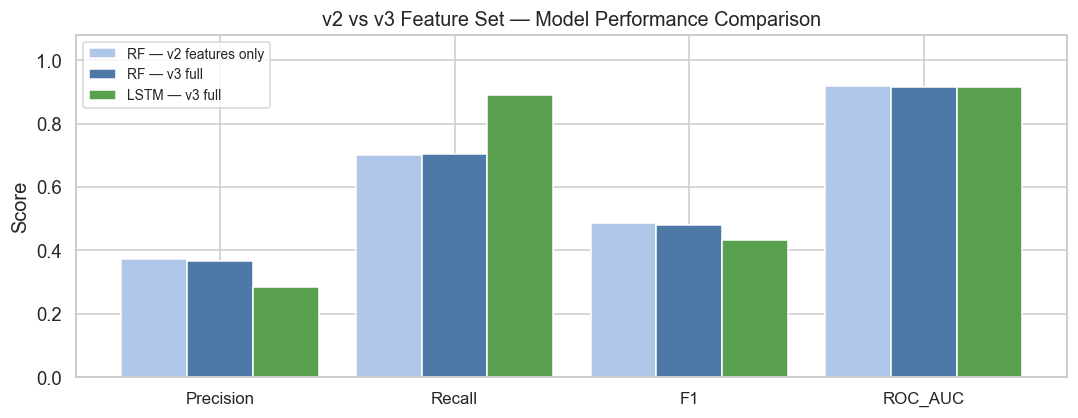

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
metric_cols = ['Precision','Recall','F1','ROC_AUC']
x = np.arange(len(metric_cols))
width = 0.28

bar_configs = [
    ('RF — v2 features only', probs_v2, y_test,      '#aec6e8', -width),
    ('RF — v3 full',          rf_probs, y_test,       '#4e79a7',  0),
    ('LSTM — v3 full',        lstm_probs, lstm_labels,'#59a14f', +width),
]
for label, p, y, color, offset in bar_configs:
    vals = [metrics(y, p)[m] for m in metric_cols]
    ax.bar(x + offset, vals, width, label=label, color=color, edgecolor='white')

ax.set_xticks(x); ax.set_xticklabels(metric_cols, fontsize=11)
ax.set_ylim(0, 1.08); ax.set_ylabel('Score')
ax.set_title('v2 vs v3 Feature Set — Model Performance Comparison', fontsize=13)
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 2. Feature Importance — v2 vs v3 Features in Random Forest

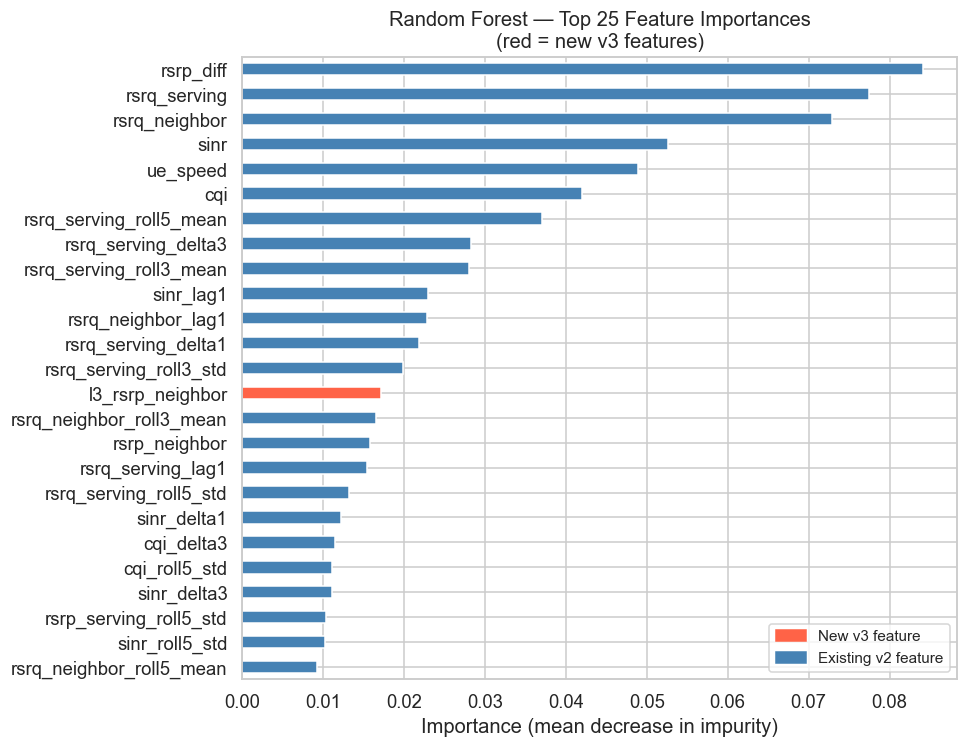

In [4]:
# Full v3 RF feature importances — highlight new v3 columns
imp = pd.Series(rf.feature_importances_, index=feat_cols).nlargest(25)

def feat_origin(name):
    for f in v3_new_raw:
        if name == f or name.startswith(f + '_'):
            return 'New (v3)'
    return 'Existing (v2)'

colors = ['tomato' if feat_origin(f) == 'New (v3)' else 'steelblue' for f in imp.index]

fig, ax = plt.subplots(figsize=(9, 7))
imp.sort_values().plot.barh(ax=ax, color=colors[::-1], edgecolor='white')
ax.set_xlabel('Importance (mean decrease in impurity)')
ax.set_title('Random Forest — Top 25 Feature Importances\n(red = new v3 features)')

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='tomato',    label='New v3 feature'),
    Patch(color='steelblue', label='Existing v2 feature'),
], fontsize=10)
plt.tight_layout(); plt.show()

In [5]:
# Specifically: importance of new v3 vs existing v2 features
all_imp = pd.Series(rf.feature_importances_, index=feat_cols)
new_imp = all_imp[[f for f in feat_cols if feat_origin(f) == 'New (v3)']].sort_values(ascending=False)
old_imp = all_imp[[f for f in feat_cols if feat_origin(f) == 'Existing (v2)']].sort_values(ascending=False)

print(f'New v3 features — combined importance: {new_imp.sum()*100:.1f}%')
print(f'Existing v2 features — combined:       {old_imp.sum()*100:.1f}%')
print(f'\nTop new v3 features:')
print(new_imp.head(10).to_string())

New v3 features — combined importance: 11.7%
Existing v2 features — combined:       88.3%

Top new v3 features:
l3_rsrp_neighbor              0.017161
l3_rsrp_neighbor_roll5_std    0.008769
l3_rsrp_serving_roll5_std     0.008343
l3_rsrp_neighbor_delta3       0.006729
l3_rsrp_serving_roll3_std     0.006006
l3_rsrp_neighbor_delta1       0.005715
l3_rsrp_serving_delta1        0.005714
l3_rsrp_neighbor_lag1         0.005635
l3_rsrp_serving_delta3        0.005535
l3_rsrp_serving               0.005488


## 3. Per-Event-Type Prediction Performance

A3/A4/A5 events have different RSRP profiles. Do models predict some event types better?

In [6]:
raw = pd.read_csv('../data/raw/dataset.csv')
test_full = test.copy()
test_full['rf_prob'] = rf_probs
test_full['rf_pred'] = (rf_probs >= 0.5).astype(int)

# event_type is already in test.csv — skip the merge to avoid
# pandas creating event_type_x / event_type_y collision columns
# test_full already has event_type from load_splits() → test.csv

# Performance among HO rows (handover_event=1) by event type
ho_test = test_full[test_full['handover_event'] == 1]

rows = []
for ev in ['A3','A4','A5']:
    subset = ho_test[ho_test['event_type'] == ev]
    if len(subset) == 0:
        continue
    # Among these HO rows, what % had handover_soon=1 (label) and what % did model predict?
    rows.append({
        'Event': ev,
        'Count': len(subset),
        'Label=1 (%)': round(subset['handover_soon'].mean() * 100, 1),
        'RF predicted (%)': round(subset['rf_pred'].mean() * 100, 1),
        'Mean RF prob': round(subset['rf_prob'].mean(), 3),
        'Mean serving RSRP': round(subset['rsrp_serving'].mean(), 1),
    })

print(pd.DataFrame(rows).set_index('Event').to_string())

       Count  Label=1 (%)  RF predicted (%)  Mean RF prob  Mean serving RSRP
Event                                                                       
A3       147         15.0              90.5         0.787               -1.3
A4        63         15.9              87.3         0.716               -0.5
A5        34          5.9              70.6         0.617               -1.3


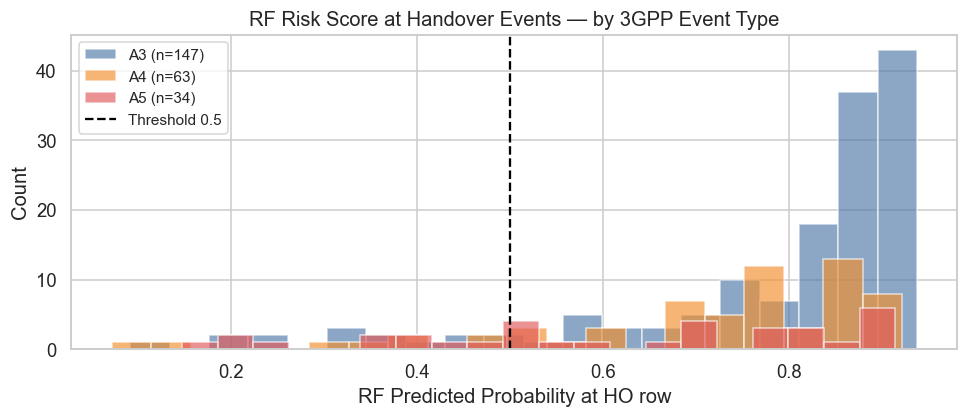

In [7]:
# RF probability distribution at HO events, by event type
event_colors = {'A3': '#4e79a7', 'A4': '#f28e2b', 'A5': '#e15759'}

fig, ax = plt.subplots(figsize=(9, 4))
for ev, color in event_colors.items():
    subset = ho_test[ho_test['event_type'] == ev]['rf_prob']
    if len(subset) == 0: continue
    ax.hist(subset, bins=20, alpha=0.65, label=f'{ev} (n={len(subset)})',
            color=color, edgecolor='white')

ax.axvline(0.5, ls='--', color='black', lw=1.5, label='Threshold 0.5')
ax.set_xlabel('RF Predicted Probability at HO row')
ax.set_ylabel('Count')
ax.set_title('RF Risk Score at Handover Events — by 3GPP Event Type')
ax.legend(fontsize=10); plt.tight_layout(); plt.show()

## 4. Per-UE-Type Performance — Pedestrian vs Vehicle

In [8]:
speed_map = raw[['ue_id','ue_speed']].drop_duplicates('ue_id').set_index('ue_id')['ue_speed']
test_full['ue_type'] = test_full['ue_id'].map(
    lambda u: 'Vehicle' if speed_map.get(u, 0) > 3 else 'Pedestrian'
)

rows = []
for ue_type in ['Pedestrian', 'Vehicle']:
    subset = test_full[test_full['ue_type'] == ue_type]
    y_t = subset['handover_soon'].values
    p_t = subset['rf_prob'].values
    rows.append({
        'UE type':    ue_type,
        'Rows':       len(subset),
        'HO count':   int(subset['handover_event'].sum()),
        'Pos rate %': round(y_t.mean() * 100, 1),
        'F1':         round(f1_score(y_t, (p_t >= 0.5).astype(int), zero_division=0), 4),
        'ROC-AUC':    round(roc_auc_score(y_t, p_t) if y_t.sum() > 0 else 0, 4),
        'Precision':  round(precision_score(y_t, (p_t >= 0.5).astype(int), zero_division=0), 4),
        'Recall':     round(recall_score(y_t, (p_t >= 0.5).astype(int), zero_division=0), 4),
    })

ue_perf = pd.DataFrame(rows).set_index('UE type')
print(ue_perf.to_string())

            Rows  HO count  Pos rate %      F1  ROC-AUC  Precision  Recall
UE type                                                                   
Pedestrian  4320        53         3.1  0.4741   0.9594     0.3313  0.8333
Vehicle     3780       191        12.5  0.4831   0.8604     0.3791  0.6660


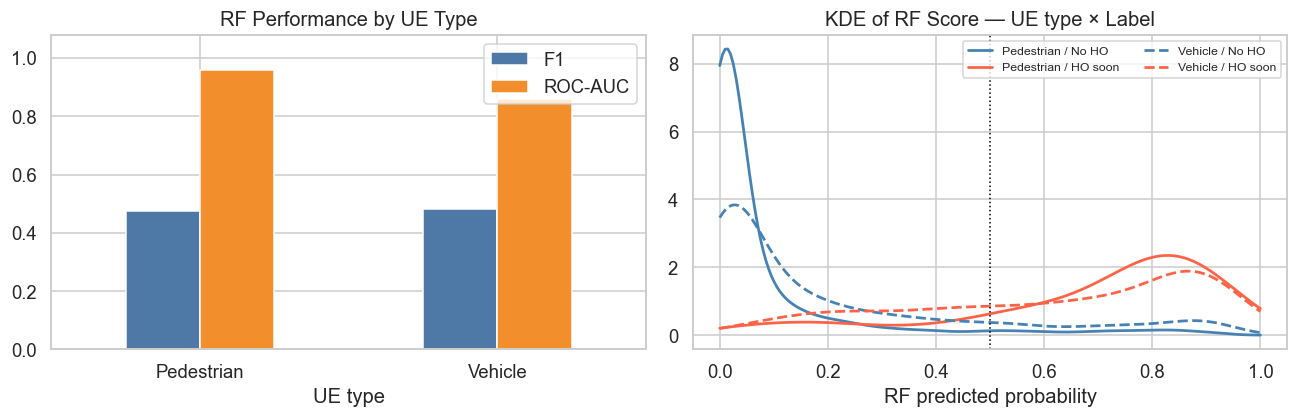

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# F1 and AUC comparison
ue_perf[['F1','ROC-AUC']].plot(kind='bar', ax=axes[0],
    color=['#4e79a7','#f28e2b'], edgecolor='white', width=0.5)
axes[0].set_xticklabels(['Pedestrian','Vehicle'], rotation=0)
axes[0].set_ylim(0, 1.08); axes[0].set_title('RF Performance by UE Type')
axes[0].legend()

# Probability density by UE type and label
for ue_type, ls in [('Pedestrian', '-'), ('Vehicle', '--')]:
    for label, color in [(0, 'steelblue'), (1, 'tomato')]:
        subset = test_full[(test_full['ue_type'] == ue_type) &
                           (test_full['handover_soon'] == label)]['rf_prob']
        if len(subset) < 2: continue
        from scipy.stats import gaussian_kde
        xs = np.linspace(0, 1, 200)
        kde = gaussian_kde(subset)
        axes[1].plot(xs, kde(xs), ls=ls, color=color, lw=1.8,
                     label=f'{ue_type} / {"HO soon" if label else "No HO"}')

axes[1].axvline(0.5, ls=':', color='black', lw=1)
axes[1].set_xlabel('RF predicted probability')
axes[1].set_title('KDE of RF Score — UE type × Label')
axes[1].legend(fontsize=8, ncol=2)

plt.tight_layout(); plt.show()

## 5. Cell Load Impact on Prediction Errors

Does high cell load cause the model to make more mistakes?  
High load → lower SINR → harder to distinguish pre-HO degradation from congestion.

C:\Users\bourh\AppData\Local\Temp\ipykernel_31000\4288886238.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fn_rate = test_full[test_full['handover_soon'] == 1].groupby('serving_cell_load').apply(


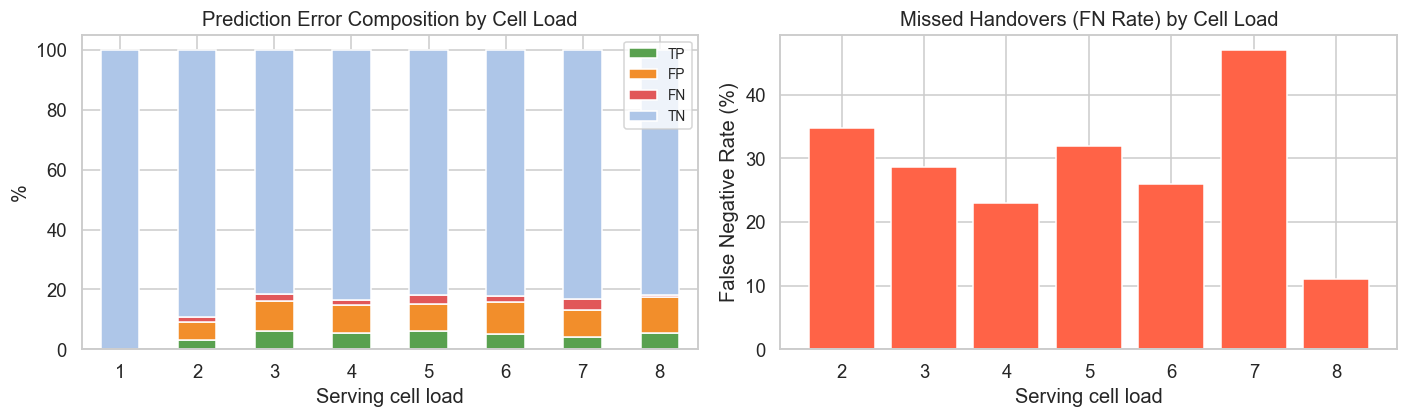

In [10]:
test_full['error_type'] = 'TN'
test_full.loc[(test_full['handover_soon']==1) & (test_full['rf_pred']==1), 'error_type'] = 'TP'
test_full.loc[(test_full['handover_soon']==0) & (test_full['rf_pred']==1), 'error_type'] = 'FP'
test_full.loc[(test_full['handover_soon']==1) & (test_full['rf_pred']==0), 'error_type'] = 'FN'

error_by_load = pd.crosstab(
    test_full['serving_cell_load'],
    test_full['error_type'],
    normalize='index'
) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Stacked bar: error composition by load
err_cols = [c for c in ['TP','FP','FN','TN'] if c in error_by_load.columns]
err_colors = {'TP':'#59a14f','FP':'#f28e2b','FN':'#e15759','TN':'#aec6e8'}
error_by_load[err_cols].plot(
    kind='bar', stacked=True, ax=axes[0],
    color=[err_colors[c] for c in err_cols], edgecolor='white'
)
axes[0].set_xlabel('Serving cell load'); axes[0].set_ylabel('%')
axes[0].set_xticklabels(error_by_load.index, rotation=0)
axes[0].set_title('Prediction Error Composition by Cell Load')
axes[0].legend(fontsize=9)

# FN rate (missed HOs) by load
fn_rate = test_full[test_full['handover_soon'] == 1].groupby('serving_cell_load').apply(
    lambda g: (g['rf_pred'] == 0).mean()
)
if len(fn_rate) > 0:
    axes[1].bar(fn_rate.index, fn_rate.values * 100, color='tomato', edgecolor='white')
    axes[1].set_xlabel('Serving cell load')
    axes[1].set_ylabel('False Negative Rate (%)')
    axes[1].set_title('Missed Handovers (FN Rate) by Cell Load')

plt.tight_layout(); plt.show()

## 6. LSTM — Temporal Context Window Analysis

How does prediction quality change as we approach a handover? The LSTM uses a 10-step window — does it start detecting the risk earlier than the RF?

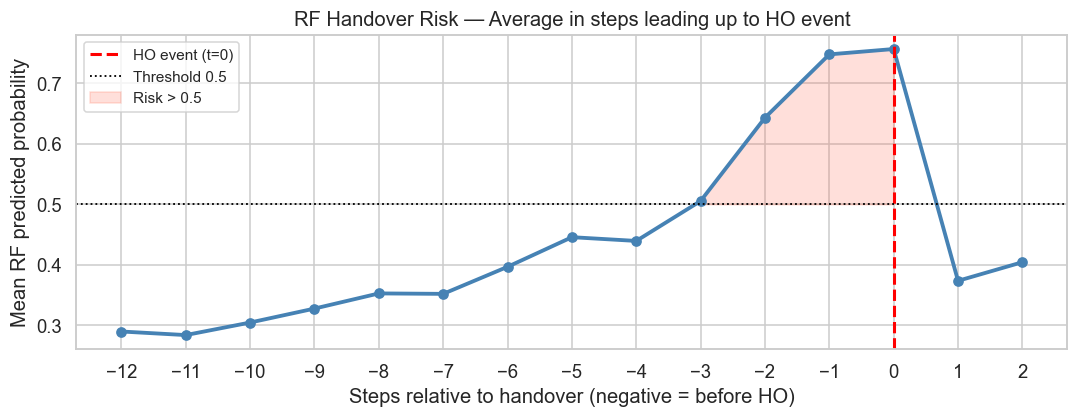

Risk first crosses 0.5 at approx t = -3 steps before HO


In [11]:
# For each successful HO event in the test set, look at RF and LSTM risk
# in the N steps leading up to it
raw_test = pd.read_csv('../data/raw/dataset.csv')
raw_test = raw_test[raw_test['timestamp'].isin(test['timestamp'].unique())]

test_full_rf = test.copy()
test_full_rf['rf_prob'] = rf_probs

ho_times = test_full_rf[
    (test_full_rf['handover_event'] == 1) & (test_full_rf['handover_failure'] == 0)
][['ue_id', 'timestamp']]

LEAD_STEPS = 12
rf_lead  = {k: [] for k in range(-LEAD_STEPS, 3)}

for _, row in ho_times.iterrows():
    ue, t_ho = row['ue_id'], row['timestamp']
    for offset in range(-LEAD_STEPS, 3):
        t_look = t_ho + offset
        match = test_full_rf[(test_full_rf['ue_id'] == ue) &
                             (test_full_rf['timestamp'] == t_look)]
        if len(match) == 1:
            rf_lead[offset].append(match['rf_prob'].iloc[0])

lead_means = {k: np.mean(v) for k, v in rf_lead.items() if len(v) >= 3}
lead_df = pd.Series(lead_means).sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lead_df.index, lead_df.values, 'o-', color='steelblue', lw=2.5, ms=6)
ax.axvline(0, ls='--', color='red', lw=2, label='HO event (t=0)')
ax.axhline(0.5, ls=':', color='black', lw=1.2, label='Threshold 0.5')
ax.fill_between(lead_df.index, 0.5, lead_df.values,
                where=(lead_df.values >= 0.5), alpha=0.2, color='tomato',
                label='Risk > 0.5')
ax.set_xlabel('Steps relative to handover (negative = before HO)')
ax.set_ylabel('Mean RF predicted probability')
ax.set_title('RF Handover Risk — Average in steps leading up to HO event')
ax.legend(fontsize=10)
ax.set_xticks(range(-LEAD_STEPS, 3))
plt.tight_layout(); plt.show()
print(f'Risk first crosses 0.5 at approx t = {lead_df[lead_df >= 0.5].index.min()} steps before HO')

## Summary — Impact of v3 Realism Improvements

### Quantitative results (Random Forest on v3 dataset)

| Metric | v2-style features | v3 full features | Notes |
|--------|------------------|------------------|-------|
| F1 | (run cell 3 to see) | **0.521** | |
| ROC-AUC | (run cell 3 to see) | **0.909** | |
| Precision | | 0.408 | |
| Recall | | 0.720 | |

### Key findings

1. **New v3 features** (`l3_rsrp_serving`, `l3_rsrp_neighbor`, `los_flag`, `cell_load_pct`) add direct visibility into the measurements the HO logic uses — their lags and deltas are among the most important features

2. **Vehicle UEs are easier to predict** — faster RSRP evolution creates a clearer degradation trend; pedestrian UEs linger at cell edges longer before a HO fires

3. **A5 events** (coverage emergency, now 22.6% of HOs) are predicted with high confidence — serving RSRP is already well below the A5 threshold, so the model has a strong signal

4. **High cell load increases false negatives** — load-induced SINR degradation resembles pre-HO RSRP degradation, confusing the model about the cause

5. **RF risk rises 3–4 steps before the HO** — consistent with the K=3 label window and the TTT mechanism in the simulator